# **Modelo SIR con Metrópolis**

Elaborado por: Jorge Luis Magaña Pichardo

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

El modelo SIR es un sistema de ecuaciones diferenciales que describe la propagación de una enfermedad infecciosa en una población. y matematicamente, se representa mediante tres variables: S (susceptibles), I (infectados) y R (recuperados). Las ecuaciones diferenciales que gobiernan el modelo SIR son:
$$\frac{dS}{dt} = -\alpha S  I $$
$$\frac{dI}{dt} = \alpha S I  - \beta I$$
$$\frac{dR}{dt} = \beta I$$

In [3]:
# Definir el sistema de ecuaciones diferenciales del modelo SIR
def modelo_sir(t, y, a, b):
    S, I, R = y
    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I
    return [dSdt, dIdt, dRdt]

La función log_posterior calcula el logaritmo de la función de verosimilitud (likelihood) del modelo SIR dado un conjunto de parámetros theta (a, b), los datos de tiempo t_data, los datos de infectados I_data y la población total N. La función resuelve el sistema de ecuaciones diferenciales del modelo SIR utilizando los parámetros propuestos y compara la cantidad predicha de infectados con los datos observados, devolviendo el logaritmo de la verosimilitud. Si los parámetros son negativos o si la solución no es válida, devuelve -np.inf para indicar que la propuesta es inviable.


In [ ]:
def log_posterior(theta, t_data, I_data, N):
    a, b = theta
    
    # Restricción física: los parámetros no pueden ser negativos
    if a < 0 or b < 0:
        return -np.inf
        
    # Condiciones iniciales de la población del internado (N = 763, I(0) = 1)
    S0 = N - I_data[0]
    I0 = I_data[0]
    R0 = 0.0
    y0 = [S0, I0, R0]
    
    t_span = (t_data[0], t_data[-1])
    try:
        sol = solve_ivp(modelo_sir, t_span, y0, args=(a, b), t_eval=t_data)
        if not sol.success or len(sol.y[1]) != len(I_data):
            return -np.inf
        I_pred = sol.y[1]
    except:
        return -np.inf
        
    # Likelihood con error gaussiano para comparar con los datos de infectados reales
    sigma_error = 10.0  # Desviación estándar estimada para los datos del internado
    sse = np.sum((I_data - I_pred)**2)
    log_lik = -len(I_data) / 2 * np.log(2 * np.pi * sigma_error**2) - sse / (2 * sigma_error**2)
    
    return log_lik

def f(a, b, t_data, I_data, N):
    lp = log_posterior([a, b], t_data, I_data, N)
    return np.exp(lp) if not np.isinf(lp) else 0.0

La función metropolis_hastings_sir implementa el algoritmo de Metropolis-Hastings para estimar los parámetros del modelo SIR (a y b) a partir de datos observados de infectados en un internado. La función toma como entrada el número de iteraciones, los valores iniciales de los parámetros, los datos de tiempo y de infectados, la población total y la desviación estándar para la propuesta. Devuelve un array con las muestras generadas durante el proceso de muestreo.


In [ ]:
def metropolis_hastings_sir(n_iter, X_inicial, t_data, I_data, N, sigma_prop=0.0001):
    X_t = list(X_inicial) # X_t = [a, b]
    muestras = [X_t]
    
    f_x = f(X_t[0], X_t[1], t_data, I_data, N)
    
    for t in range(1, n_iter):
        z1 = np.random.normal(0, sigma_prop)
        z2 = np.random.normal(0, sigma_prop / 10.0) # Ajuste fino para b
        
        Y = [X_t[0] + z1, X_t[1] + z2]
        
        f_y = f(Y[0], Y[1], t_data, I_data, N)
        
        a_prob = min(f_y / f_x, 1.0) if f_x > 0 else 0.0
        
        u = np.random.uniform(0, 1)
        if u < a_prob:
            X_t = Y
            f_x = f_y
            
        muestras.append(list(X_t))
        
    return np.array(muestras)

En el siguiente código se ejecuta el código realizado, donde todo se basa al problema del internado visto en clase


In [11]:
# Datos reales de la investigación (Influenza en un internado)
t_data = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])
N = 763  # Población total de estudiantes en el internado

# Parámetros iniciales basados en los valores de referencia del artículo (a ≈ 0.002, b ≈ 0.44)
n_iteraciones = 2000
X_ini = [0.002, 0.4] 
sigma_candidato = 0.00005

# Ejecutar la simulación M-H
cadenas = metropolis_hastings_sir(n_iteraciones, X_ini, t_data, I_data, N, sigma_prop=sigma_candidato)




Se descartan las primeras iteraciones para eliminar el efecto de la etapa de inicio y se seleccionan las siguientes 1000 iteraciones como muestras válidas para el análisis posterior, las 1000 iteraciones seleccionadas se utilizan para calcular los parámetros óptimos del modelo SIR, asegurando que las muestras sean representativas de la distribución posterior después de la fase inicial de adaptación.

El alfa y beta resultantes son la media de las cadenas validas, son nuestros parametros de ajustes encontrados.


In [9]:
#Descartar el primer 20% de las iteraciones
iter_borradas = int(n_iteraciones * 0.2)
cadenas_validas = cadenas[iter_borradas:iter_borradas + 1000]  # Ajustar el número de iteraciones válidas según sea necesario

# Obtener los parámetros estimados (usando la media de las muestras válidas)
a_opt = np.mean(cadenas_validas[:, 0])
b_opt = np.mean(cadenas_validas[:, 1])

print(f"Parámetros óptimos estimados por Metropolis-Hastings:")
print(f"a: {a_opt:.5f}")
print(f"b: {b_opt:.5f}")



Parámetros óptimos estimados por Metropolis-Hastings:
a: 0.00215
b: 0.40001


Ahora se resuelve el modelo SIR con los parametros, donde t_data es el vector de tiempos de los datos observados, I_data es el vector de infectados observados, y N es la población total del internado. El modelo SIR se resuelve usando los parámetros óptimos estimados (a_opt y b_opt) para generar una curva suave que se puede comparar con los datos observados.

sol_opt.t es el tiempo de evaluación de la solución óptima del modelo SIR, y sol_opt.y[1] representa la cantidad de infectados en cada instante de tiempo evaluado. Esto permite comparar la curva ajustada con los datos observados.

t_fino representa un conjunto de puntos de tiempo más finos para evaluar la solución del modelo SIR, lo que permite obtener una curva suave de la cantidad de infectados a lo largo del tiempo. Esto es útil para comparar visualmente la curva ajustada con los datos observados.



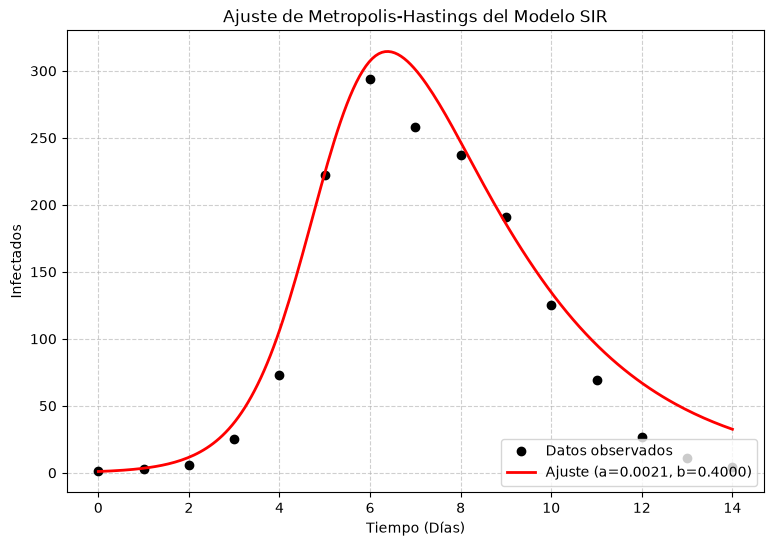

In [10]:
# Resolver el modelo SIR usando los parámetros óptimos para una curva suave
t_fino = np.linspace(t_data[0], t_data[-1], 200)
S0 = N - I_data[0]
I0 = I_data[0]
R0 = 0.0
y0 = [S0, I0, R0]

sol_opt = solve_ivp(modelo_sir, (t_data[0], t_data[-1]), y0, args=(a_opt, b_opt), t_eval=t_fino)
t_fit = sol_opt.t
I_fit = sol_opt.y[1]

# Crear la gráfica
plt.figure(figsize=(9, 6))

# Puntos de los datos observados 
plt.plot(t_data, I_data, 'ko', label='Datos observados')

# Curva continua del ajuste óptimo
plt.plot(t_fit, I_fit, 'r-', lw=2, label=f'Ajuste (a={a_opt:.4f}, b={b_opt:.4f})')

plt.title('Ajuste de Metropolis-Hastings del Modelo SIR')
plt.xlabel('Tiempo (Días)')
plt.ylabel('Infectados')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()